<a href="https://colab.research.google.com/github/arkaanrobbani09/Automotive-Engine-Remaining-Useful-Life-RUL-Prediction/blob/main/RUL_Mesin_Mobil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RUL Prediction - Sensor Mesin Mobil


In [ ]:
!pip install tensorflow scikit-learn shap matplotlib numpy -q

## 1. Import Library

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap
import warnings
warnings.filterwarnings('ignore')
print('Library berhasil diimport!')

Library berhasil diimport!


## 2. Pembuatan Data Sintetis Sensor Mesin Mobil

In [ ]:
def generate_rul_data(num_engines=150, max_cycles=200, seq_len=30):
    """
    Data sintetis sensor mesin mobil untuk prediksi RUL.
    Sensor: oil_pressure, engine_temp, vibration, rpm_deviation, fuel_flow, exhaust_temp
    Target: RUL (sisa siklus hidup, dinormalisasi ke [0,1])
    """
    np.random.seed(42)
    X_all, y_all = [], []

    for engine_id in range(num_engines):
        total_cycles = np.random.randint(100, max_cycles)
        for start_cycle in range(0, total_cycles - seq_len):
            cycles = np.arange(start_cycle, start_cycle + seq_len)
            degradation = cycles / total_cycles

            oil_pressure  = 4.0 - 1.5 * degradation**1.5 + np.random.randn(seq_len) * 0.15
            engine_temp   = 90  + 40  * degradation**2   + np.random.randn(seq_len) * 3.0
            vibration     = 0.1 + 0.9 * degradation**1.2 + np.random.randn(seq_len) * 0.05
            rpm_deviation = 5   + 80  * degradation**2   + np.random.randn(seq_len) * 5.0
            fuel_flow     = 8.0 + 3.0 * degradation**1.8 + np.random.randn(seq_len) * 0.3
            exhaust_temp  = 300 + 150 * degradation**1.5 + np.random.randn(seq_len) * 10.0

            seq = np.stack([oil_pressure, engine_temp, vibration,
                            rpm_deviation, fuel_flow, exhaust_temp], axis=1)
            rul = total_cycles - (start_cycle + seq_len)
            X_all.append(seq)
            y_all.append(rul)

    X = np.array(X_all, dtype=np.float32)
    y = np.array(y_all, dtype=np.float32)
    y_max = y.max()
    return X, y / y_max, y_max

X, y, y_max = generate_rul_data()
SENSOR_NAMES = ['Oil Pressure', 'Engine Temp', 'Vibration', 'RPM Deviation', 'Fuel Flow', 'Exhaust Temp']

print(f'Total sampel  : {X.shape[0]}')
print(f'Panjang urutan: {X.shape[1]} siklus')
print(f'Jumlah sensor : {X.shape[2]}')
print(f'Rentang RUL   : {(y * y_max).min():.0f} - {(y * y_max).max():.0f} siklus')

Total sampel  : 18521
Panjang urutan: 30 siklus
Jumlah sensor : 6
Rentang RUL   : 1 - 169 siklus


## 3. Visualisasi Data Sintetis

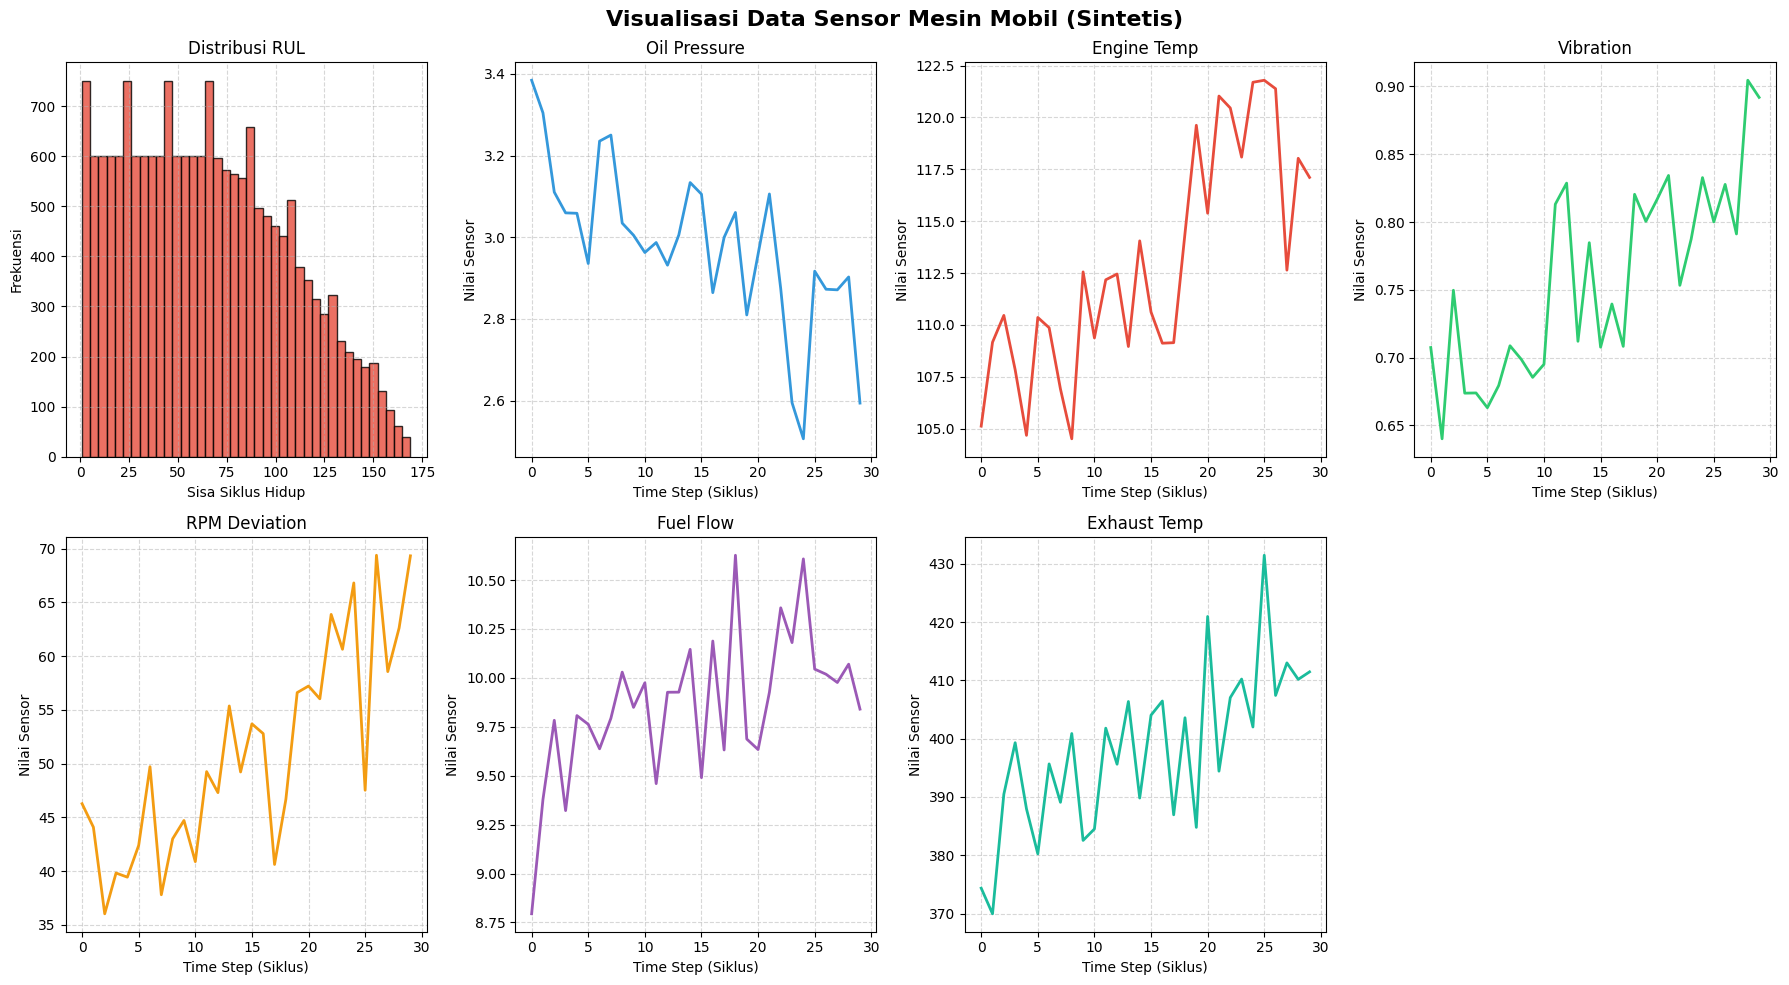

In [ ]:
fig = plt.figure(figsize=(18, 10))
fig.suptitle('Visualisasi Data Sensor Mesin Mobil (Sintetis)', fontsize=16, fontweight='bold')

ax_rul = fig.add_subplot(2, 4, 1)
ax_rul.hist(y * y_max, bins=40, color='#E74C3C', edgecolor='black', alpha=0.8)
ax_rul.set_title('Distribusi RUL')
ax_rul.set_xlabel('Sisa Siklus Hidup')
ax_rul.set_ylabel('Frekuensi')
ax_rul.grid(True, linestyle='--', alpha=0.5)

colors = ['#3498DB', '#E74C3C', '#2ECC71', '#F39C12', '#9B59B6', '#1ABC9C']
for i, (name, color) in enumerate(zip(SENSOR_NAMES, colors)):
    ax = fig.add_subplot(2, 4, i + 2)
    ax.plot(X[100, :, i], color=color, linewidth=2)
    ax.set_title(name)
    ax.set_xlabel('Time Step (Siklus)')
    ax.set_ylabel('Nilai Sensor')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Arsitektur Transformer-RNN
**Alur:** Input → Multi-Head Attention → LayerNorm → Feed Forward → LSTM → Dense(sigmoid) → RUL

In [ ]:
def build_transformer_rnn(seq_len, n_features, num_heads=2, ff_dim=64,
                           rnn_units=64, dropout=0.1, learning_rate=0.001):
    inputs = layers.Input(shape=(seq_len, n_features))

    # Transformer Block
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=n_features)(inputs, inputs)
    attn_out = layers.Dropout(dropout)(attn_out)
    x = layers.LayerNormalization(epsilon=1e-6)(inputs + attn_out)
    ff = layers.Dense(ff_dim, activation='relu')(x)
    ff = layers.Dense(n_features)(ff)
    ff = layers.Dropout(dropout)(ff)
    x = layers.LayerNormalization(epsilon=1e-6)(x + ff)

    # LSTM Block
    x = layers.LSTM(rnn_units, return_sequences=False)(x)
    x = layers.Dropout(dropout)(x)

    # Output
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='mse', metrics=['mae'])
    return model

sample_model = build_transformer_rnn(X.shape[1], X.shape[2])
sample_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 6)     │        330 │ input_layer[0][0… │
│ (MultiHeadAttentio… │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 6)     │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 6)     │          0 │ input_layer[0][0… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 6)     │         12 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 64)    │        448 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 30, 6)     │        390 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 30, 6)     │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 6)     │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 6)     │         12 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     18,176 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,433 (75.91 KB)

 Trainable params: 19,433 (75.91 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Analisis Bias-Variance (Baseline) + Hyperparameter Tuning K-Fold

In [ ]:
param_grid = [
    {'num_heads': 2, 'rnn_units': 32,  'ff_dim': 32,  'lr': 0.001,  'label': 'Baseline (Kecil)'},
    {'num_heads': 4, 'rnn_units': 64,  'ff_dim': 64,  'lr': 0.001,  'label': 'Medium'},
    {'num_heads': 4, 'rnn_units': 128, 'ff_dim': 128, 'lr': 0.0005, 'label': 'Besar (Complex)'},
]
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# Baseline bias-variance
baseline_params = param_grid[0]
b_train_losses, b_val_losses = [], []
for train_idx, val_idx in kf.split(X):
    m = build_transformer_rnn(X.shape[1], X.shape[2],
                               num_heads=baseline_params['num_heads'],
                               rnn_units=baseline_params['rnn_units'],
                               ff_dim=baseline_params['ff_dim'],
                               learning_rate=baseline_params['lr'])
    hist = m.fit(X[train_idx], y[train_idx], epochs=10, batch_size=64, verbose=0,
                 validation_data=(X[val_idx], y[val_idx]))
    b_train_losses.append(hist.history['loss'][-1])
    b_val_losses.append(hist.history['val_loss'][-1])

gap_b = np.mean(b_val_losses) - np.mean(b_train_losses)
print(f'[Baseline] Train MSE: {np.mean(b_train_losses):.5f} | Val MSE: {np.mean(b_val_losses):.5f} | Gap: {gap_b:.5f}')
if np.mean(b_train_losses) > 0.05:
    print('-> HIGH BIAS (Underfitting)')
elif gap_b > 0.02:
    print('-> HIGH VARIANCE (Overfitting)')
else:
    print('-> GOOD TRADE-OFF ✓')

[Baseline] Train MSE: 0.00679 | Val MSE: 0.00681 | Gap: 0.00002
-> GOOD TRADE-OFF ✓


In [ ]:
tuning_results = []
best_params = None
best_val_loss = float('inf')

for params in param_grid:
    fold_train_losses, fold_val_losses, fold_train_maes, fold_val_maes = [], [], [], []
    for train_idx, val_idx in kf.split(X):
        m = build_transformer_rnn(X.shape[1], X.shape[2],
                                   num_heads=params['num_heads'],
                                   rnn_units=params['rnn_units'],
                                   ff_dim=params['ff_dim'],
                                   learning_rate=params['lr'])
        hist = m.fit(X[train_idx], y[train_idx], epochs=12, batch_size=64, verbose=0,
                     validation_data=(X[val_idx], y[val_idx]))
        fold_train_losses.append(hist.history['loss'][-1])
        fold_val_losses.append(hist.history['val_loss'][-1])
        fold_train_maes.append(hist.history['mae'][-1])
        fold_val_maes.append(hist.history['val_mae'][-1])

    avg_tr = np.mean(fold_train_losses)
    avg_vl = np.mean(fold_val_losses)
    tuning_results.append({'label': params['label'], 'params': params,
                            'train_loss': avg_tr, 'val_loss': avg_vl,
                            'train_mae': np.mean(fold_train_maes), 'val_mae': np.mean(fold_val_maes),
                            'gap': avg_vl - avg_tr})
    print(f"[{params['label']}] Train: {avg_tr:.5f} | Val: {avg_vl:.5f} | Gap: {avg_vl - avg_tr:.5f}")
    if avg_vl < best_val_loss:
        best_val_loss = avg_vl
        best_params = params

print(f'\n=> Parameter Terbaik: {best_params["label"]} | Val Loss: {best_val_loss:.5f}')

[Baseline (Kecil)] Train: 0.00668 | Val: 0.00653 | Gap: -0.00015
[Medium] Train: 0.00632 | Val: 0.00650 | Gap: 0.00018
[Besar (Complex)] Train: 0.00587 | Val: 0.00738 | Gap: 0.00151

=> Parameter Terbaik: Medium | Val Loss: 0.00650


## 6. Visualisasi Bias-Variance

[Baseline (Kecil)] Train: 0.00668 | Val: 0.00653 | Gap: -0.00015 -> GOOD TRADE-OFF ✓
[Medium] Train: 0.00632 | Val: 0.00650 | Gap: 0.00018 -> GOOD TRADE-OFF ✓
[Besar (Complex)] Train: 0.00587 | Val: 0.00738 | Gap: 0.00151 -> GOOD TRADE-OFF ✓


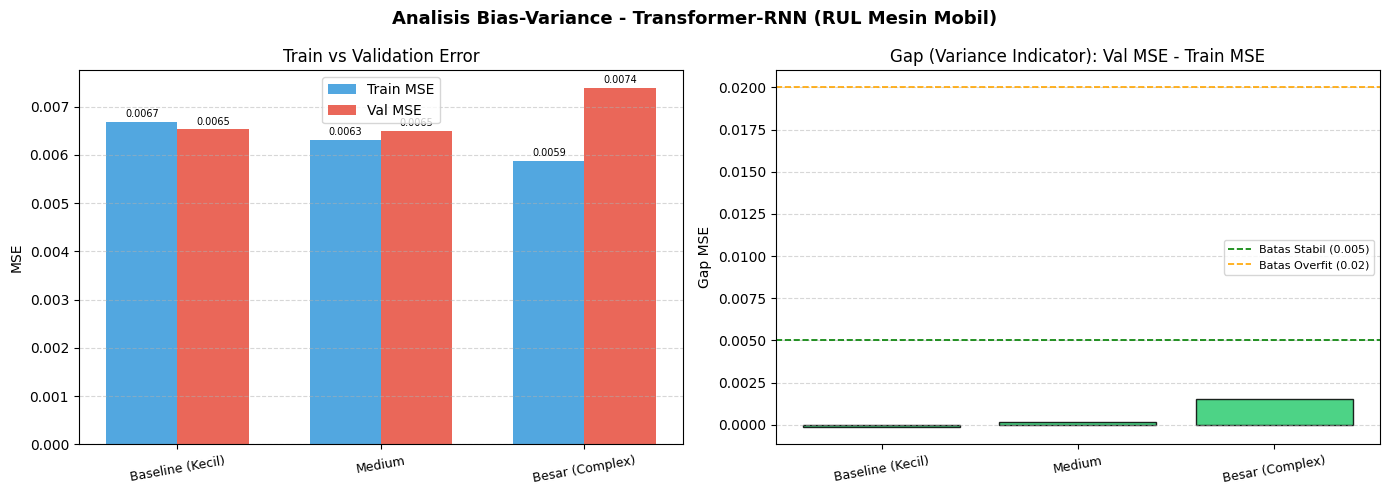

In [ ]:
labels     = [r['label']      for r in tuning_results]
train_errs = [r['train_loss'] for r in tuning_results]
val_errs   = [r['val_loss']   for r in tuning_results]
gaps       = [r['gap']        for r in tuning_results]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Analisis Bias-Variance - Transformer-RNN (RUL Mesin Mobil)', fontsize=13, fontweight='bold')

x_pos = np.arange(len(labels))
width = 0.35
ax = axes[0]
bars1 = ax.bar(x_pos - width/2, train_errs, width, label='Train MSE', color='#3498DB', alpha=0.85)
bars2 = ax.bar(x_pos + width/2, val_errs,   width, label='Val MSE',   color='#E74C3C', alpha=0.85)
ax.set_title('Train vs Validation Error')
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=10, fontsize=9)
ax.set_ylabel('MSE')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
for bar in bars1: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0001, f'{bar.get_height():.4f}', ha='center', fontsize=7)
for bar in bars2: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0001, f'{bar.get_height():.4f}', ha='center', fontsize=7)

ax2 = axes[1]
bar_colors = ['#2ECC71' if g < 0.005 else '#F39C12' if g < 0.02 else '#E74C3C' for g in gaps]
ax2.bar(labels, gaps, color=bar_colors, edgecolor='black', alpha=0.85)
ax2.axhline(0.005, color='green',  linestyle='--', linewidth=1.2, label='Batas Stabil (0.005)')
ax2.axhline(0.02,  color='orange', linestyle='--', linewidth=1.2, label='Batas Overfit (0.02)')
ax2.set_title('Gap (Variance Indicator): Val MSE - Train MSE')
ax2.set_ylabel('Gap MSE')
ax2.set_xticklabels(labels, rotation=10, fontsize=9)
ax2.legend(fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')

for res in tuning_results:
    diag = 'HIGH BIAS' if res['train_loss'] > 0.05 else 'HIGH VARIANCE' if res['gap'] > 0.02 else 'GOOD TRADE-OFF ✓'
    print(f"[{res['label']}] Train: {res['train_loss']:.5f} | Val: {res['val_loss']:.5f} | Gap: {res['gap']:.5f} -> {diag}")

plt.tight_layout()
plt.show()

## 7. Evaluasi Kestabilan K-Fold + Train-Test Split

In [ ]:
best_fold_mse, best_fold_mae = [], []
for fold_num, (train_idx, val_idx) in enumerate(kf.split(X)):
    m = build_transformer_rnn(X.shape[1], X.shape[2],
                               num_heads=best_params['num_heads'],
                               rnn_units=best_params['rnn_units'],
                               ff_dim=best_params['ff_dim'],
                               learning_rate=best_params['lr'])
    m.fit(X[train_idx], y[train_idx], epochs=15, batch_size=64, verbose=0)
    loss, mae = m.evaluate(X[val_idx], y[val_idx], verbose=0)
    best_fold_mse.append(loss)
    best_fold_mae.append(mae)
    print(f'  Fold {fold_num+1}: Val MSE = {loss:.5f} | Val MAE = {mae:.4f}')

mean_mse = np.mean(best_fold_mse)
std_mse  = np.std(best_fold_mse)
mean_mae = np.mean(best_fold_mae)
std_mae  = np.std(best_fold_mae)
print(f'\nMean Val MSE: {mean_mse:.5f} ± {std_mse:.5f}')
print(f'Mean Val MAE: {mean_mae:.4f} ± {std_mae:.4f} (~{mean_mae * y_max:.1f} siklus)')

if std_mse < 0.002:
    print('-> STABIL: variasi antar fold sangat rendah.')
elif std_mse < 0.01:
    print('-> CUKUP STABIL: variasi antar fold masih wajar.')
else:
    print('-> TIDAK STABIL: pertimbangkan regularisasi lebih.')

  Fold 1: Val MSE = 0.00811 | Val MAE = 0.0684
  Fold 2: Val MSE = 0.00800 | Val MAE = 0.0697
  Fold 3: Val MSE = 0.00678 | Val MAE = 0.0618

Mean Val MSE: 0.00763 ± 0.00060
Mean Val MAE: 0.0667 ± 0.0035 (~11.3 siklus)
-> STABIL: variasi antar fold sangat rendah.


Test MSE: 0.00703 | Test MAE: 0.0625 (~10.6 siklus)


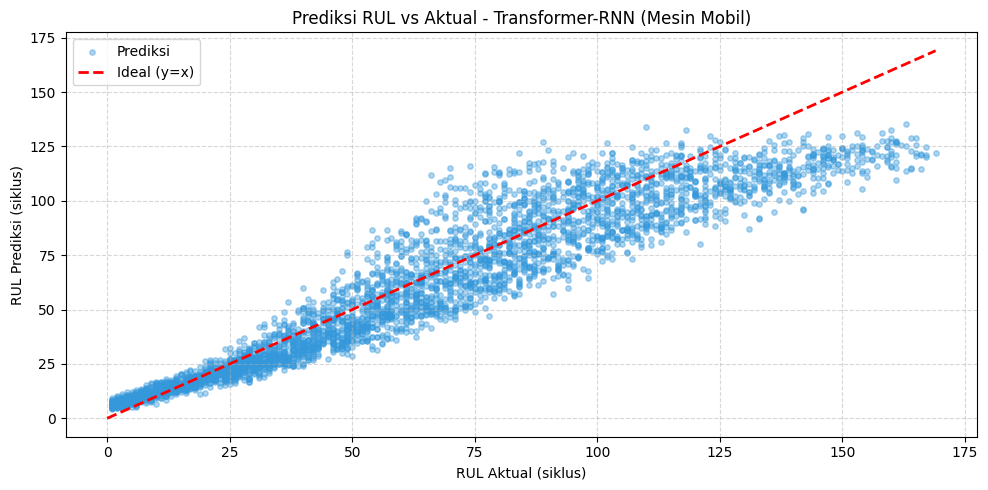

In [ ]:
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(X, y, test_size=0.2, random_state=42)
m_tt = build_transformer_rnn(X.shape[1], X.shape[2],
                              num_heads=best_params['num_heads'],
                              rnn_units=best_params['rnn_units'],
                              ff_dim=best_params['ff_dim'],
                              learning_rate=best_params['lr'])
m_tt.fit(X_tr_s, y_tr_s, epochs=15, batch_size=64, verbose=0)
loss_tt, mae_tt = m_tt.evaluate(X_te_s, y_te_s, verbose=0)
print(f'Test MSE: {loss_tt:.5f} | Test MAE: {mae_tt:.4f} (~{mae_tt * y_max:.1f} siklus)')

y_pred_tt = m_tt.predict(X_te_s, verbose=0).flatten() * y_max
y_true_tt = y_te_s * y_max

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(y_true_tt, y_pred_tt, alpha=0.4, s=15, color='#3498DB', label='Prediksi')
ax.plot([0, y_true_tt.max()], [0, y_true_tt.max()], 'r--', linewidth=2, label='Ideal (y=x)')
ax.set_xlabel('RUL Aktual (siklus)')
ax.set_ylabel('RUL Prediksi (siklus)')
ax.set_title('Prediksi RUL vs Aktual - Transformer-RNN (Mesin Mobil)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 8. Analisis SHAP - Interpretasi Model

Model final selesai dilatih.


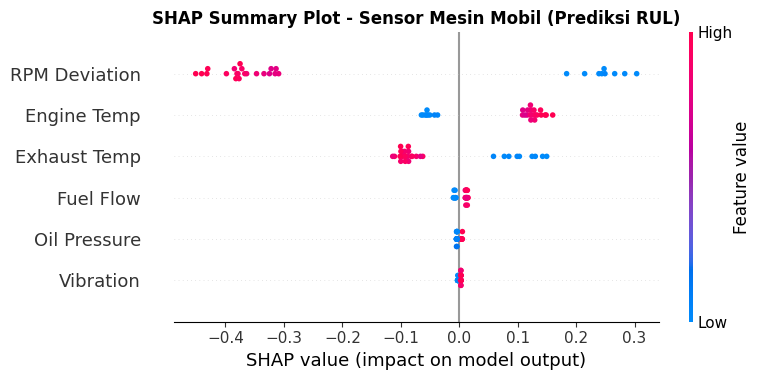

In [ ]:
final_model = build_transformer_rnn(X.shape[1], X.shape[2],
                                     num_heads=best_params['num_heads'],
                                     rnn_units=best_params['rnn_units'],
                                     ff_dim=best_params['ff_dim'],
                                     learning_rate=best_params['lr'])
final_model.fit(X, y, epochs=20, batch_size=64, verbose=0)
print('Model final selesai dilatih.')

background    = X[:100]
explainer     = shap.GradientExplainer(final_model, background)
X_test_sample = X[100:130]
shap_values   = explainer.shap_values(X_test_sample)

shap_squeezed  = shap_values.squeeze(-1)
shap_2d        = np.sum(np.abs(shap_squeezed), axis=1)
mean_importance = shap_2d.mean(axis=0)
sorted_idx     = np.argsort(mean_importance)[::-1]

shap_2d_signed = np.sum(shap_squeezed, axis=1)
X_test_2d      = X_test_sample.mean(axis=1)
shap.summary_plot(shap_2d_signed, X_test_2d, feature_names=SENSOR_NAMES, show=False)
plt.title('SHAP Summary Plot - Sensor Mesin Mobil (Prediksi RUL)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

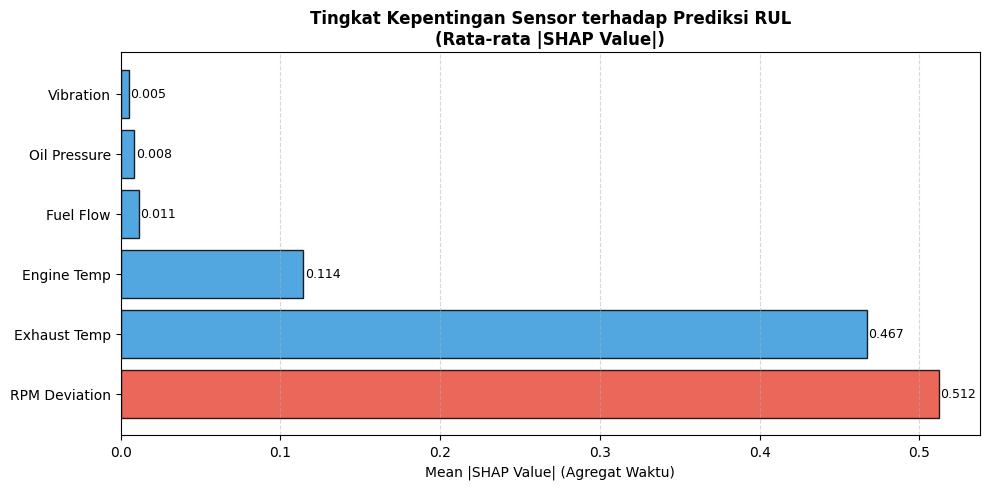


=== RANKING KEPENTINGAN SENSOR ===
  #1 RPM Deviation     : 0.5121
  #2 Exhaust Temp      : 0.4670
  #3 Engine Temp       : 0.1144
  #4 Fuel Flow         : 0.0112
  #5 Oil Pressure      : 0.0084
  #6 Vibration         : 0.0051


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sorted_names = [SENSOR_NAMES[i] for i in sorted_idx]
sorted_imp   = mean_importance[sorted_idx]
bars = ax.barh(sorted_names, sorted_imp,
               color=['#E74C3C' if i == 0 else '#3498DB' for i in range(len(sorted_names))],
               edgecolor='black', alpha=0.85)
ax.set_title('Tingkat Kepentingan Sensor terhadap Prediksi RUL\n(Rata-rata |SHAP Value|)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Mean |SHAP Value| (Agregat Waktu)')
ax.grid(True, linestyle='--', alpha=0.5, axis='x')
for bar, val in zip(bars, sorted_imp):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print('\n=== RANKING KEPENTINGAN SENSOR ===')
for rank, idx in enumerate(sorted_idx):
    print(f'  #{rank+1} {SENSOR_NAMES[idx]:<18}: {mean_importance[idx]:.4f}')

## 9. Ringkasan Hasil

In [ ]:
print('=' * 60)
print('  RINGKASAN HASIL - RUL PREDICTION MESIN MOBIL')
print('=' * 60)
print(f'  Parameter Terbaik    : {best_params["label"]}')
print(f'    num_heads          : {best_params["num_heads"]}')
print(f'    rnn_units (LSTM)   : {best_params["rnn_units"]}')
print(f'    ff_dim (Transformer): {best_params["ff_dim"]}')
print(f'    learning_rate      : {best_params["lr"]}')
print(f'\n  Performa (K-Fold):')
print(f'    Val MSE : {mean_mse:.5f} ± {std_mse:.5f}')
print(f'    Val MAE : {mean_mae:.4f} ± {std_mae:.4f} (~{mean_mae * y_max:.1f} siklus)')
print(f'\n  Performa (Test Split):')
print(f'    Test MSE: {loss_tt:.5f}')
print(f'    Test MAE: {mae_tt:.4f} (~{mae_tt * y_max:.1f} siklus)')
print(f'\n  Sensor Paling Berpengaruh (SHAP):')
for rank, idx in enumerate(sorted_idx):
    print(f'    #{rank+1} {SENSOR_NAMES[idx]:<18}: {mean_importance[idx]:.4f}')
print('=' * 60)

  RINGKASAN HASIL - RUL PREDICTION MESIN MOBIL
  Parameter Terbaik    : Medium
    num_heads          : 4
    rnn_units (LSTM)   : 64
    ff_dim (Transformer): 64
    learning_rate      : 0.001

  Performa (K-Fold):
    Val MSE : 0.00763 ± 0.00060
    Val MAE : 0.0667 ± 0.0035 (~11.3 siklus)

  Performa (Test Split):
    Test MSE: 0.00703
    Test MAE: 0.0625 (~10.6 siklus)

  Sensor Paling Berpengaruh (SHAP):
    #1 RPM Deviation     : 0.5121
    #2 Exhaust Temp      : 0.4670
    #3 Engine Temp       : 0.1144
    #4 Fuel Flow         : 0.0112
    #5 Oil Pressure      : 0.0084
    #6 Vibration         : 0.0051
